# Ames Housing: Simple and Multiple Linear Regression

**Dataset:** Ames Housing (`housing.csv`)

## Objectives
1. Fit Simple Linear Regression using one predictor.
2. Fit Multiple Linear Regression using several predictors.
3. Interpret regression coefficients.
4. Evaluate both models using MSE and R².

The dataset contains 2,930 records and 83 columns in this supplied file. `SalePrice` is the target. Identifier columns are not used as predictors. Missing values in selected predictors are handled with median imputation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# In Kaggle, add the dataset and update this path if needed.
from pathlib import Path
candidates = [Path('housing.csv'), Path('/mnt/data/housing.csv')]
# If using Kaggle, search attached dataset files.
if not any(p.exists() for p in candidates):
    candidates += list(Path('/kaggle/input').glob('**/housing.csv')) if Path('/kaggle/input').exists() else []
if not any(p.exists() for p in candidates):
    raise FileNotFoundError('Place housing.csv in the working directory or attach it as a Kaggle dataset.')
dataset_path = next(p for p in candidates if p.exists())
df = pd.read_csv(dataset_path)
print('Loaded:', dataset_path)
print('Shape:', df.shape)
print(df.head())
print('Missing cells:', int(df.isna().sum().sum()))

Loaded: /mnt/data/housing.csv
Shape: (2930, 83)
   Unnamed: 0  Order        PID  ...  Sale Type Sale Condition  SalePrice
0           0      1  526301100  ...        WD          Normal     215000
1           1      2  526350040  ...        WD          Normal     105000
2           2      3  526351010  ...        WD          Normal     172000
3           3      4  526353030  ...        WD          Normal     244000
4           4      5  527105010  ...        WD          Normal     189900

[5 rows x 83 columns]
Missing cells: 15749


## 1. Inspect the data

The file contains mixed numerical and categorical columns. This experiment selects numerical predictors and does not treat record identifiers as meaningful explanatory variables. The target is `SalePrice`.

In [2]:
print(df[['SalePrice', 'Overall Qual', 'Gr Liv Area', 'Garage Cars', 'Total Bsmt SF']].describe().round(2))
print('\nMissing values in selected columns:')
print(df[['SalePrice'] + ['Overall Qual','Gr Liv Area','Garage Cars','Total Bsmt SF','Year Built','Full Bath','Lot Area','1st Flr SF','Bedroom AbvGr','Fireplaces']].isna().sum())

       SalePrice  Overall Qual  Gr Liv Area  Garage Cars  Total Bsmt SF
count    2930.00       2930.00      2930.00      2929.00        2929.00
mean   180796.06          6.09      1499.69         1.77        1051.61
std     79886.69          1.41       505.51         0.76         440.62
min     12789.00          1.00       334.00         0.00           0.00
25%    129500.00          5.00      1126.00         1.00         793.00
50%    160000.00          6.00      1442.00         2.00         990.00
75%    213500.00          7.00      1742.75         2.00        1302.00
max    755000.00         10.00      5642.00         5.00        6110.00

Missing values in selected columns:
SalePrice        0
Overall Qual     0
Gr Liv Area      0
Garage Cars      1
Total Bsmt SF    1
Year Built       0
Full Bath        0
Lot Area         0
1st Flr SF       0
Bedroom AbvGr    0
Fireplaces       0
dtype: int64


## 2. Prepare predictors and split the data

`Overall Qual` is used for simple regression. Multiple regression uses ten numerical features. An 80/20 train-test split is used with a fixed random seed. Median imputation is fitted inside each model pipeline, using the training data.

In [3]:
target = 'SalePrice'
slr_feature = 'Overall Qual'
features = ['Overall Qual','Gr Liv Area','Garage Cars','Total Bsmt SF','Year Built','Full Bath','Lot Area','1st Flr SF','Bedroom AbvGr','Fireplaces']
X = df[features].apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(df[target], errors='coerce')
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))

Training rows: 2344 | Test rows: 586


## 3. Simple Linear Regression

The model uses overall quality as the single predictor of sale price. The fitted coefficient estimates the average change in predicted sale price for a one-point increase in overall quality.

In [4]:
slr = make_pipeline(SimpleImputer(strategy='median'), LinearRegression())
slr.fit(X_train[[slr_feature]], y_train)
pred_slr = slr.predict(X_test[[slr_feature]])
slr_mse = mean_squared_error(y_test, pred_slr)
slr_r2 = r2_score(y_test, pred_slr)
model_slr = slr.named_steps['linearregression']
print(f'Intercept: ${model_slr.intercept_:,.2f}')
print(f'Coefficient for {slr_feature}: ${model_slr.coef_[0]:,.2f}')
print(f'Test MSE: {slr_mse:,.2f}')
print(f'Test R²: {slr_r2:.4f}')

Intercept: $-89,311.54
Coefficient for Overall Qual: $44,174.67
Test MSE: 2,796,154,624.89
Test R²: 0.6512


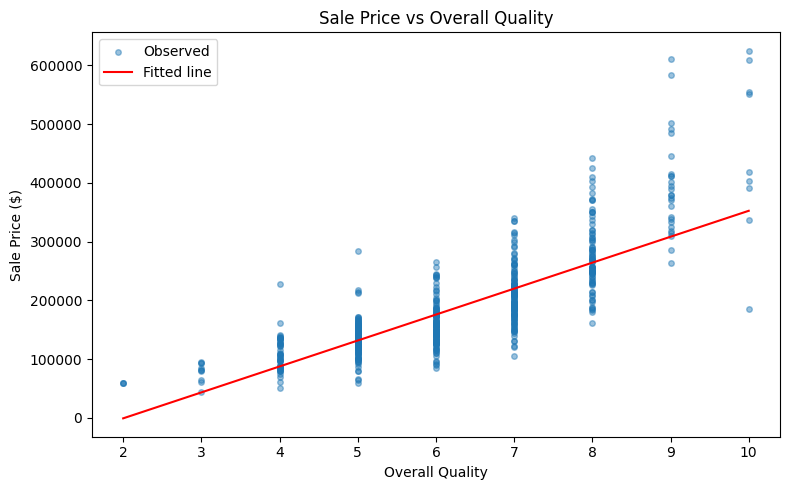

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test[slr_feature], y_test, alpha=0.45, s=16, label='Observed')
xs = np.linspace(X_test[slr_feature].min(), X_test[slr_feature].max(), 100)
plt.plot(xs, model_slr.intercept_ + model_slr.coef_[0] * xs, color='red', label='Fitted line')
plt.xlabel('Overall Quality'); plt.ylabel('Sale Price ($)'); plt.title('Sale Price vs Overall Quality')
plt.legend(); plt.tight_layout(); plt.show()

## 4. Multiple Linear Regression

The multiple model combines ten selected numerical features. Each coefficient describes the estimated change in sale price associated with a one-unit increase in that feature while the other included features are held constant. Correlated predictors can make individual coefficients less stable.

In [6]:
mlr = make_pipeline(SimpleImputer(strategy='median'), LinearRegression())
mlr.fit(X_train, y_train)
pred_mlr = mlr.predict(X_test)
mlr_mse = mean_squared_error(y_test, pred_mlr)
mlr_r2 = r2_score(y_test, pred_mlr)
coefs = pd.Series(mlr.named_steps['linearregression'].coef_, index=features).sort_values(ascending=False)
print('Intercept:', f'${mlr.named_steps["linearregression"].intercept_:,.2f}')
print('\nCoefficients:')
print(coefs.round(2))
print(f'\nTest MSE: {mlr_mse:,.2f}')
print(f'Test R²: {mlr_r2:.4f}')

Intercept: $-799,911.91

Coefficients:
Overall Qual     20121.13
Garage Cars      11365.09
Fireplaces        6211.59
Year Built         376.94
Gr Liv Area         55.68
Total Bsmt SF       20.37
1st Flr SF           4.70
Lot Area             0.67
Full Bath        -3789.75
Bedroom AbvGr    -7266.51
dtype: float64

Test MSE: 1,516,970,795.32
Test R²: 0.8108


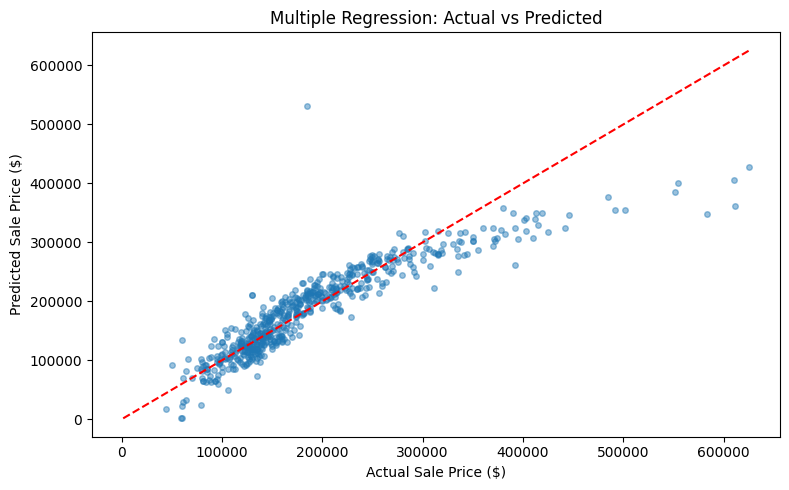

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, pred_mlr, alpha=0.45, s=16)
lo, hi = min(y_test.min(), pred_mlr.min()), max(y_test.max(), pred_mlr.max())
plt.plot([lo, hi], [lo, hi], 'r--')
plt.xlabel('Actual Sale Price ($)'); plt.ylabel('Predicted Sale Price ($)')
plt.title('Multiple Regression: Actual vs Predicted'); plt.tight_layout(); plt.show()

## 5. Compare the models

MSE measures average squared prediction error in dollars squared, so lower is better. R² measures the proportion of test-set target variation explained by the model, with higher values indicating a better fit for this test set.

                     Model          MSE     R2
  Simple Linear Regression 2.796155e+09 0.6512
Multiple Linear Regression 1.516971e+09 0.8108


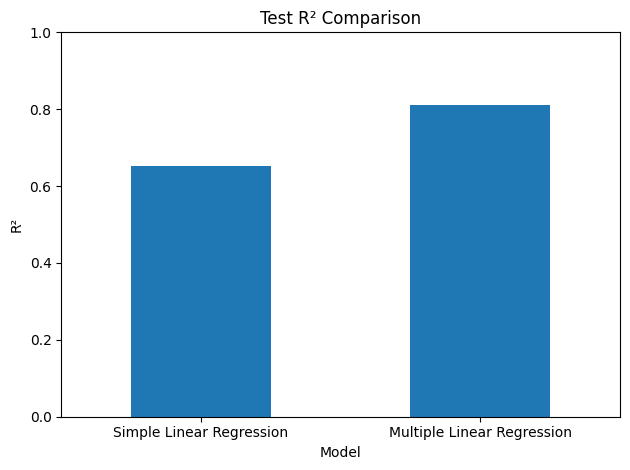

In [8]:
results = pd.DataFrame({'Model':['Simple Linear Regression','Multiple Linear Regression'], 'MSE':[slr_mse,mlr_mse], 'R2':[slr_r2,mlr_r2]})
print(results.round(4).to_string(index=False))
results.plot(x='Model', y='R2', kind='bar', legend=False, ylim=(0,1), title='Test R² Comparison', rot=0)
plt.ylabel('R²'); plt.tight_layout(); plt.show()

## 6. Findings and conclusion

- Overall quality is a useful single predictor of sale price, but it does not capture all property differences.
- The multiple regression model uses more property information and achieves a higher test-set R² on this split.
- Median imputation allows selected predictors with missing entries to be used without discarding all affected rows.
- Coefficients describe associations within this linear model, not proof of causation.
- The models provide a baseline. Nonlinear models and careful feature engineering could improve performance.

**Conclusion:** Multiple Linear Regression performed better than Simple Linear Regression on the same held-out test set for this supplied Ames Housing file.